# MLP：CPU / RTX 4080 SUPER

在 Jupyter 中选择 **Python (makemore CUDA)** 内核，再从上到下运行。

保留当前实验：字符 embedding 为 2 维、隐藏层为 300、batch size 为 32。前 30,000 步学习率 0.1，后 10,000 步为 0.01。

第一个代码单元格会显示实际使用的设备。可以把 `device` 改为 `torch.device("cpu")` 来比较速度；这个小模型也适合单线程 CPU。


In [1]:
import os
import time
import torch
import random
import matplotlib.pyplot as plt
F = torch.nn.functional

# 小矩阵计算使用太多 CPU 线程反而可能更慢。
torch.set_num_threads(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))


PyTorch: 2.10.0+cu126
Device: cuda
GPU: NVIDIA GeForce RTX 4080 SUPER


In [2]:
with open("names.txt", "r+") as file:
    contents = file.read()

split_lines = contents.splitlines()
random.seed(42)
random.shuffle(split_lines)
char_set = sorted(set(''.join(split_lines)))


In [3]:
g = torch.Generator(device=device).manual_seed(2147483647)
C = torch.randn((27, 2), requires_grad=True, generator=g, device=device)
W1 = torch.randn((6, 300), requires_grad=True, generator=g, device=device)
B1 = torch.randn((300,), requires_grad=True, generator=g, device=device)
W2 = torch.randn((300, 27), requires_grad=True, generator=g, device=device)
B2 = torch.randn((27,), requires_grad=True, generator=g, device=device)
block_size = 3

parameters = list([C, W1, B1, W2, B2])

ch2i = {}
i2ch = {}
ch2i['.'] = 0
i2ch[0] = '.'

for i, v in enumerate(char_set):
    ch2i[v] = i + 1
    i2ch[i + 1] = v

In [4]:
def convert_names(names):
    converted = []
    X = []
    Y = []
    for v in names:
        added = list(v)
        context = ['.'] * block_size
        for target in added + ['.']:
            nums = []
            for c in context:
                nums.append(ch2i[c])
            X.append(nums)
            Y.append(ch2i[target])
            converted.append((context, target))
            context = context[1:] + [target]
    tx = torch.tensor(X, dtype=torch.long, device=device)
    ty = torch.tensor(Y, dtype=torch.long, device=device)
    return tx, ty

In [5]:
train_set = int(0.8 * len(split_lines))
dev_set = train_set + int(0.1 * len(split_lines))
test_set = dev_set + int(0.1 * len(split_lines))

Xtr, Ytr = convert_names(split_lines[0:train_set])
Xdev, Ydev = convert_names(split_lines[train_set:dev_set])
Xtest, Ytest = convert_names(split_lines[dev_set:])

torch.cat([C[5], C[13], C[13]])
dim_N_6 = []

In [6]:
# 修改这三个值即可调整实验；两阶段训练之间不会重新初始化模型。
steps_high = 30000
steps_low = 10000
batch_size = 32
steps = steps_high + steps_low

# loss 留在计算设备上，训练结束后再一次性转回 CPU。
# 避免每一步 loss.item() 都等待 GPU 完成计算。
loss_buffer = torch.empty(steps, device=device)
if device.type == "cuda":
    torch.cuda.synchronize()
started = time.perf_counter()

for i in range(steps):
    batch_indices = torch.randint(0, len(Xtr), (batch_size,), device=device)
    batch_x = Xtr[batch_indices]
    batch_y = Ytr[batch_indices]
    dim_N_6 = C[batch_x].view(-1, 6)
    hidden = torch.tanh(dim_N_6 @ W1 + B1)
    logits = hidden @ W2 + B2
    loss = F.cross_entropy(logits, batch_y)
    loss_buffer[i] = loss.detach()

    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 if i < steps_high else 0.01
    with torch.no_grad():
        for p in parameters:
            p.add_(p.grad, alpha=-lr)

    if (i + 1) % 5000 == 0:
        print(f"step {i + 1}/{steps}, lr={lr}, batch loss={loss.item():.4f}")

if device.type == "cuda":
    torch.cuda.synchronize()
elapsed = time.perf_counter() - started
lossi = loss_buffer.cpu().tolist()
print(f"Training: {elapsed:.2f} s, {1000 * elapsed / steps:.3f} ms/step")


step 5000/40000, lr=0.1, batch loss=2.9249


step 10000/40000, lr=0.1, batch loss=2.5302


step 15000/40000, lr=0.1, batch loss=2.3930


step 20000/40000, lr=0.1, batch loss=2.9563


step 25000/40000, lr=0.1, batch loss=2.9721


step 30000/40000, lr=0.1, batch loss=2.8941


step 35000/40000, lr=0.01, batch loss=2.2078


step 40000/40000, lr=0.01, batch loss=2.2741
Training: 25.33 s, 0.633 ms/step


In [7]:
# 评估时无需构建反向传播图。
with torch.no_grad():
    dim_N_6 = C[Xtr].view(-1, 6)
    hidden = torch.tanh(dim_N_6 @ W1 + B1)
    logits = hidden @ W2 + B2
    loss_train = F.cross_entropy(logits, Ytr)

    dim_N_6_dev = C[Xdev].view(-1, 6)
    hidden_dev = torch.tanh(dim_N_6_dev @ W1 + B1)
    logits_dev = hidden_dev @ W2 + B2
    loss_dev = F.cross_entropy(logits_dev, Ydev)

print(f"train loss: {loss_train.item():.4f}")
print(f"dev loss:   {loss_dev.item():.4f}")


train loss: 2.3179
dev loss:   2.3144


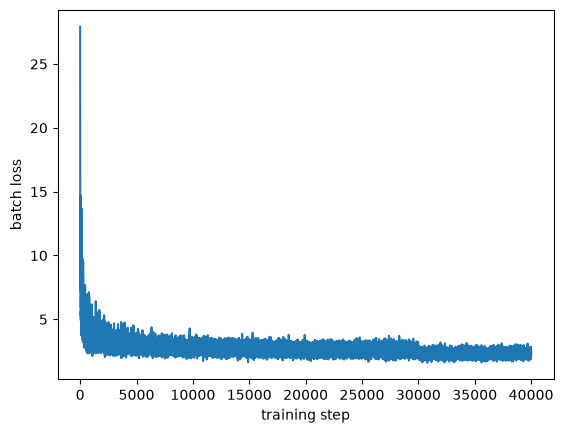

In [8]:
plt.plot(lossi)
plt.xlabel("training step")
plt.ylabel("batch loss")
plt.show()
